# Seq2Seq: The Waiter Who Takes No Notes 🍽️

**Picture this.** A proud waiter never writes anything down. They listen to your whole order, keep it in their head, walk to the kitchen, and write out the ticket from memory.

That is exactly how a **sequence-to-sequence (Seq2Seq)** model works:

```
 "two burgers and a coke please"            "1 coke 2 burger"
              │                                     ▲
              ▼                                     │
      ┌───────────────┐    one fixed-size    ┌───────────────┐
      │    ENCODER    │ ───  memory  ──────▶ │    DECODER    │
      │ (listens word │     (a vector)       │ (writes word  │
      │   by word)    │                      │   by word)    │
      └───────────────┘                      └───────────────┘
```

| In the restaurant | In the model | What it does |
|---|---|---|
| Customer's sentence | **Source sequence** | The input, any length |
| Waiter listening | **Encoder** (a GRU) | Reads one word at a time, updating its memory |
| What's in the waiter's head | **Context vector** | The *only* thing passed to the decoder |
| Waiter writing the ticket | **Decoder** (another GRU) | Produces one word at a time from that memory |
| "Ticket's done" | **`<eos>`** token | Tells the decoder to stop |

**Our task:** turn a spoken order into a kitchen ticket. The kitchen wants **drinks first, then mains, then desserts**, so words must be rewritten *and* reordered.

> **By the end you'll see** the waiter is great at short orders and falls apart on long ones. Keep that in mind: it's why Notebook 2 exists.

## 1. Setup

This needs `torch` and `matplotlib`. The whole notebook takes about 30 seconds on a GPU. Without one it falls back to the CPU and takes longer.

In [1]:
import random, time
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence, pad_packed_sequence

device = ("cuda" if torch.cuda.is_available()
          else "mps" if torch.backends.mps.is_available() else "cpu")
print("Training on:", torch.cuda.get_device_name(0) if device == "cuda" else device)

SEED = 42
PLAIN_COLOR, ATTENTION_COLOR, BIG_COLOR = "#eb6834", "#2a78d6", "#1baf7a"   # each model keeps its color
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.axisbelow": True,
                     "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10})

Training on: NVIDIA RTX PRO 6000 Blackwell Workstation Edition


## 2. The data: customers and tickets

We generate orders from a small menu, so there's nothing to download. Each order has 1 to 10 items.

In [2]:
MENU = {"drink":   ["coke", "water", "coffee", "tea", "juice", "lemonade", "milkshake", "soda"],
        "main":    ["burger", "pizza", "pasta", "salad", "steak", "taco", "sandwich", "soup"],
        "dessert": ["cake", "pie", "brownie", "cookie", "donut", "pudding", "waffle", "muffin"]}
STATION_OF = {dish: station for station, dishes in MENU.items() for dish in dishes}
NUMBER_WORDS = ["one", "two", "three", "four", "five", "six", "seven", "eight", "nine"]
OPENERS = ["hi can i get", "i would like", "we will have", "give me"]
CLOSERS = ["please", "thanks", ""]
plural = lambda dish: dish + ("es" if dish.endswith("ch") else "s")

def make_order(n_items):
    """Returns one (what the customer says, what the ticket must say) pair of word lists."""
    dishes = random.sample(list(STATION_OF), n_items)
    quantities = [random.randint(1, 9) for _ in dishes]

    said = random.choice(OPENERS).split()
    for i, (qty, dish) in enumerate(zip(quantities, dishes)):
        said.append("a" if qty == 1 and random.random() < 0.5 else NUMBER_WORDS[qty - 1])
        said.append(dish if qty == 1 else plural(dish))
        if i < n_items - 2:     said.append(random.choice([",", "and", "plus"]))
        elif i == n_items - 2:  said.append("and")
    said += random.choice(CLOSERS).split()

    # The kitchen's rule: drinks first, then mains, then desserts
    ticket = []
    for station in MENU:
        for qty, dish in zip(quantities, dishes):
            if STATION_OF[dish] == station:
                ticket += [str(qty), dish]
    return said, ticket

random.seed(0)
for n in (2, 4):
    said, ticket = make_order(n)
    print("Customer:", " ".join(said))
    print("Ticket:  ", " ".join(ticket), "\n")

Customer: give me a steak and five tacos thanks
Ticket:   1 steak 5 taco 

Customer: hi can i get nine soups plus three salads and five brownies and three milkshakes
Ticket:   3 milkshake 9 soup 3 salad 5 brownie 



Look at why this is a job for Seq2Seq and not a simple word-by-word model:

- **Different lengths:** the sentence and the ticket rarely have the same number of words.
- **Different order:** a coke mentioned last must be written first, so the waiter must hear the *whole* order before writing.
- **Words change or vanish:** "two" becomes "2", "burgers" becomes "burger", and "please" disappears.

Next we turn words into numbers. Three special tokens do some important work:

| Token | Meaning | Restaurant version |
|---|---|---|
| `<pad>` | Filler so that a batch of sentences has equal length | Blank space, ignored |
| `<sos>` | Start of sequence | "Pen on the paper, start writing" |
| `<eos>` | End of sequence | "Ticket's done" |

In [3]:
TEST_SIZES = range(1, 11)

random.seed(SEED)
train_orders = [make_order(random.randint(1, 10)) for _ in range(120_000)]
random.seed(SEED + 1)
test_bank = {n: [make_order(n) for _ in range(500)] for n in TEST_SIZES}   # never used for training

PAD, SOS, EOS = 0, 1, 2
SPECIALS = ["<pad>", "<sos>", "<eos>"]
src_words = SPECIALS + sorted({w for said, _ in train_orders for w in said})
tgt_words = SPECIALS + sorted({w for _, ticket in train_orders for w in ticket})
src_id = {w: i for i, w in enumerate(src_words)}
tgt_id = {w: i for i, w in enumerate(tgt_words)}

def make_batch(orders):
    """Turns orders into padded GPU tensors of word ids."""
    src = [torch.tensor([src_id[w] for w in said]) for said, _ in orders]
    tgt = [torch.tensor([SOS] + [tgt_id[w] for w in ticket] + [EOS]) for _, ticket in orders]
    src_len = torch.tensor([len(s) for s in src])
    return (pad_sequence(src, batch_first=True, padding_value=PAD).to(device), src_len.to(device),
            pad_sequence(tgt, batch_first=True, padding_value=PAD).to(device))

# The whole training set lives on the GPU, so grabbing a batch is instant
X_train, L_train, Y_train = make_batch(train_orders)

print(f"{len(train_orders):,} training orders | {len(src_words)} words heard | {len(tgt_words)} ticket words")
print("Batch tensor shape (orders, longest sentence):", X_train.shape)

seen = {tuple(said) for said, _ in train_orders}
overlap = {n: 100 * sum(tuple(s) in seen for s, _ in test_bank[n]) / 500 for n in (1, 3, 5, 10)}
print("Test orders that also appear in training, by order size:", {n: f"{v:.0f}%" for n, v in overlap.items()})

120,000 training orders | 77 words heard | 36 ticket words
Batch tensor shape (orders, longest sentence): torch.Size([120000, 34])
Test orders that also appear in training, by order size: {1: '98%', 3: '0%', 5: '0%', 10: '0%'}


Almost every 1-item test order also appears in training, as so few combinations exist. From 3 items up, the test orders are new. So the results on long orders below really do measure performance on unseen data.

## 3. The encoder: listening

The encoder reads the sentence one word at a time. After each word, its GRU updates its hidden state, like the waiter updating what they remember. We keep **only the final state**, the context vector.

`pack_padded_sequence` makes sure the GRU stops at each sentence's real last word, not at the padding.

In [4]:
class Encoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hidden_dim, batch_first=True)

    def forward(self, src, src_len):
        packed = pack_padded_sequence(self.embedding(src), src_len.cpu(),
                                      batch_first=True, enforce_sorted=False)
        _, memory = self.gru(packed)
        return memory          # shape: (1, batch, hidden_dim)

# The key fact of this whole notebook:
EMB_DIM, HIDDEN_DIM = 64, 128
demo = Encoder(len(src_words), EMB_DIM, HIDDEN_DIM).to(device)
for n in (1, 10):
    src, src_len, _ = make_batch([make_order(n)])
    print(f"{n:>2}-item order: {src.size(1):>2} words in -> memory of shape {tuple(demo(src, src_len).shape)}")

 1-item order:  6 words in -> memory of shape (1, 1, 128)
10-item order: 34 words in -> memory of shape (1, 1, 128)


**Same memory size for 1 item or 10 items.** The waiter's head doesn't grow with the order. Everything must be squeezed into 128 numbers. This is the famous **bottleneck**.

## 4. The decoder: writing the ticket

The decoder is a second GRU, and its starting state is the encoder's memory. Each step takes **the last word written** and the current memory, and gives back **a score for every possible next word**.

In [5]:
class Decoder(nn.Module):
    def __init__(self, vocab_size, emb_dim, hidden_dim):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD)
        self.gru = nn.GRU(emb_dim, hidden_dim, batch_first=True)
        self.to_vocab = nn.Linear(hidden_dim, vocab_size)

    def forward(self, last_word, memory):                 # one single step
        output, memory = self.gru(self.embedding(last_word).unsqueeze(1), memory)
        return self.to_vocab(output.squeeze(1)), memory   # next-word scores, updated memory

## 5. Putting them together, and teacher forcing

The decoder works differently in training and in real use:

- **Training (`forward`), teacher forcing:** after each word, a head chef shows the waiter the *correct* word before they write the next one. One early slip doesn't ruin the whole lesson, so learning is much faster.
- **Real use (`generate`):** no chef. The waiter must build on **their own previous word**, mistakes included.

In [6]:
MAX_TICKET = 27

class Seq2Seq(nn.Module):
    def __init__(self, emb_dim=EMB_DIM, hidden_dim=HIDDEN_DIM):
        super().__init__()
        self.encoder = Encoder(len(src_words), emb_dim, hidden_dim)
        self.decoder = Decoder(len(tgt_words), emb_dim, hidden_dim)

    def forward(self, src, src_len, tgt):                 # training: teacher forcing
        memory = self.encoder(src, src_len)
        all_scores = []
        for t in range(tgt.size(1) - 1):
            scores, memory = self.decoder(tgt[:, t], memory)   # always feed the CORRECT word
            all_scores.append(scores)
        return torch.stack(all_scores, dim=1), None

    @torch.no_grad()
    def generate(self, src, src_len):                     # real use: feeds itself
        memory = self.encoder(src, src_len)
        word = torch.full((src.size(0),), SOS, device=src.device)
        written = []
        for _ in range(MAX_TICKET):
            scores, memory = self.decoder(word, memory)
            word = scores.argmax(dim=1)                   # feed its OWN best guess
            written.append(word)
        return torch.stack(written, dim=1), None

## 6. Training on the GPU

In [7]:
def train_model(model, steps=2000, batch_size=512, max_lr=2e-3, on_step=None):
    optimizer = torch.optim.Adam(model.parameters(), lr=max_lr)
    schedule = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr, total_steps=steps)
    losses, start = [], time.time()
    for step in range(steps):
        if on_step: on_step(step, model)
        idx = torch.randint(0, len(X_train), (batch_size,), device=device)
        src_len = L_train[idx]
        src = X_train[idx, :src_len.max()]                       # trim unneeded padding
        tgt = Y_train[idx, :(Y_train[idx] != PAD).sum(1).max()]

        logits = model(src, src_len, tgt)[0]
        loss = F.cross_entropy(logits.reshape(-1, logits.size(-1)),   # predict each NEXT word
                               tgt[:, 1:].reshape(-1), ignore_index=PAD)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)        # RNN safety belt
        optimizer.step()
        schedule.step()
        losses.append(loss.item())
        if step % 500 == 0 or step == steps - 1:
            print(f"step {step:>4} | loss {loss.item():.3f} | {time.time() - start:5.1f}s")
    model.train_seconds = time.time() - start
    return losses

torch.manual_seed(SEED)
model = Seq2Seq().to(device)
print(f"Model size: {sum(p.numel() for p in model.parameters()):,} parameters\n")
losses = train_model(model)
print(f"\nDone in {model.train_seconds:.0f} seconds.")

Model size: 160,868 parameters



step    0 | loss 3.592 |   0.3s


step  500 | loss 1.656 |   6.1s


step 1000 | loss 0.481 |  11.9s


step 1500 | loss 0.280 |  17.1s


step 1999 | loss 0.248 |  22.8s

Done in 23 seconds.


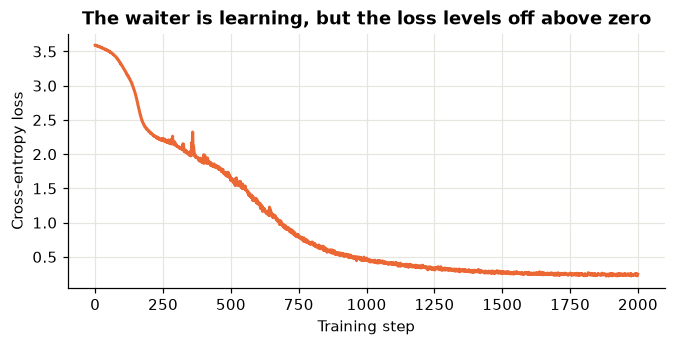

In [8]:
plt.figure(figsize=(7, 3))
plt.plot(losses, color=PLAIN_COLOR, linewidth=2)
plt.title("The waiter is learning, but the loss levels off above zero")
plt.xlabel("Training step"); plt.ylabel("Cross-entropy loss")
plt.show()

## 7. Watch the decoder think

Here is a short order, one step at a time. At each step the decoder gets the word it just wrote and scores every possible next word. These are real model probabilities.

In [9]:
def ids_to_words(ids):
    words = []
    for i in ids:
        if i == EOS: break
        if i > EOS: words.append(tgt_words[i])
    return words

def read_tickets(model, orders):
    src, src_len, _ = make_batch(orders)
    return [ids_to_words(row) for row in model.generate(src, src_len)[0].tolist()]

def split_items(ticket):
    return [(ticket[i], ticket[i + 1]) for i in range(0, len(ticket) - 1, 2)]

def score(model, bank):
    """For each order size: % perfect tickets, plus what happened to each ordered item."""
    table = {}
    for n, orders in bank.items():
        perfect = right = wrong_qty = forgot = 0
        for (_, gold), pred in zip(orders, read_tickets(model, orders)):
            perfect += pred == gold
            pred_qty = {dish: qty for qty, dish in split_items(pred)}
            for qty, dish in split_items(gold):
                if dish not in pred_qty:      forgot += 1
                elif pred_qty[dish] == qty:   right += 1
                else:                         wrong_qty += 1
        items = n * len(orders)
        table[n] = {"perfect": 100 * perfect / len(orders), "right": 100 * right / items,
                    "wrong_qty": 100 * wrong_qty / items, "forgot": 100 * forgot / items}
    return table

def tidy(text):
    """Lets you type a normal sentence. Words the waiter never heard get dropped, with a warning."""
    words = text.lower().replace(",", " , ").replace(".", " ").split()
    unknown = [w for w in words if w not in src_id]
    if unknown: print("Never heard these words, ignoring them:", unknown)
    return [w for w in words if w in src_id]

def show_ticket(gold, pred, name):
    """Prints a ticket, marking each line right or wrong against the correct ticket."""
    gold_items = split_items(gold)
    print(f"{name}:")
    for item in split_items(pred):
        print(f"   {'✓' if item in gold_items else '✗'} {item[0]} {item[1]}")
    missing = [f"{q} {d}" for q, d in gold_items if (q, d) not in split_items(pred)]
    print(f"   Should also have had: {', '.join(missing)}" if missing else "   Perfect ticket!")

@torch.no_grad()
def think_aloud(said):
    src, src_len, _ = make_batch([(said, [])])
    memory = model.encoder(src, src_len)
    word = torch.tensor([SOS], device=device)
    print("Customer:", " ".join(said), "\n")
    print(f"{'Just wrote':<12}{'Top guesses for the next word'}")
    for _ in range(MAX_TICKET):
        scores, memory = model.decoder(word, memory)
        top = F.softmax(scores, dim=1)[0].topk(3)
        guesses = "   ".join(f"{tgt_words[i]} {100 * p:.0f}%" for p, i in zip(top.values.tolist(), top.indices.tolist()))
        print(f"{tgt_words[word.item()]:<12}{guesses}")
        word = scores.argmax(dim=1)
        if word.item() == EOS or word.item() == PAD: break

think_aloud(tidy("hi can i get two burgers , a cake and three cokes please"))

Customer: hi can i get two burgers , a cake and three cokes please 

Just wrote  Top guesses for the next word
<sos>       3 100%   5 0%   2 0%
3           coke 100%   burger 0%   soda 0%
coke        2 96%   1 2%   8 1%
2           burger 100%   cake 0%   pasta 0%
burger      1 90%   8 4%   3 2%
1           cake 100%   donut 0%   pie 0%
cake        <eos> 100%   3 0%   5 0%


Notice how it **starts with the cokes**, though they were said last, and **ends with `<eos>`** on its own. No rule told it to do either. It learned from examples alone, using nothing but the memory vector.

## 8. Results: can the waiter handle a big table?

First, one short order and one long order. `✓` means that line of the ticket is correct.

In [10]:
for n, example in ((3, 2), (9, 2)):
    said, gold = test_bank[n][example]
    print(f"--- {n}-item order ---\nCustomer: {' '.join(said)}")
    show_ticket(gold, read_tickets(model, [(said, gold)])[0], "Waiter's ticket")
    print()

--- 3-item order ---
Customer: we will have five soups , four sodas and three waffles thanks
Waiter's ticket:
   ✓ 4 soda
   ✓ 5 soup
   ✓ 3 waffle
   Perfect ticket!

--- 9-item order ---
Customer: hi can i get six lemonades plus six cookies , four brownies and seven pies , five tacos plus five sandwiches plus seven waffles and a muffin and five teas
Waiter's ticket:
   ✓ 6 lemonade
   ✓ 5 tea
   ✓ 5 taco
   ✓ 5 sandwich
   ✗ 4 cookie
   ✗ 7 brownie
   ✗ 6 pie
   ✗ 1 waffle
   ✗ 7 muffin
   Should also have had: 6 cookie, 4 brownie, 7 pie, 7 waffle, 1 muffin



Now let's measure this on 500 unseen orders of each size.

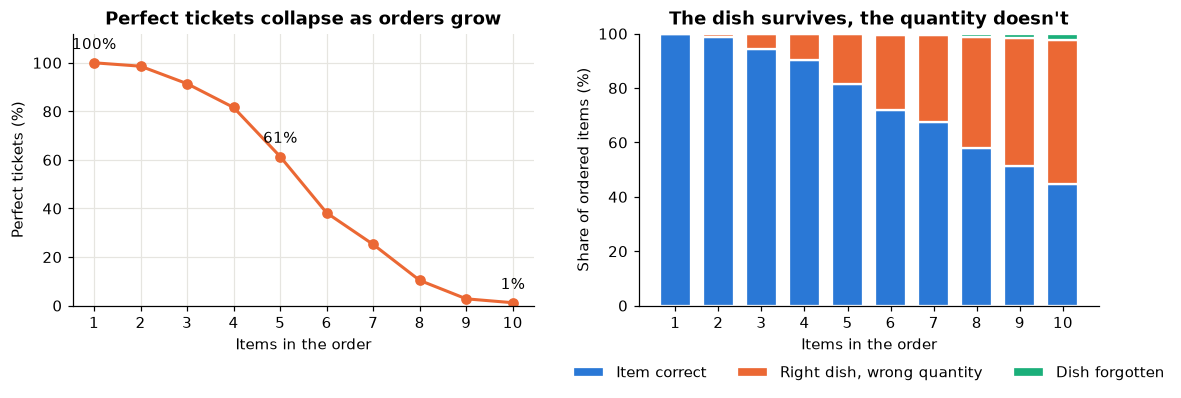

Items   Perfect  Item right  Wrong qty  Forgotten
    1    100.0%      100.0%       0.0%       0.0%
    2     98.6%       98.7%       1.3%       0.0%
    3     91.4%       94.3%       5.7%       0.0%
    4     81.6%       90.2%       9.6%       0.1%
    5     61.4%       81.3%      18.4%       0.2%
    6     38.2%       72.1%      27.4%       0.5%
    7     25.2%       67.5%      32.1%       0.4%
    8     10.4%       58.1%      40.9%       1.1%
    9      2.8%       51.4%      47.0%       1.6%
   10      1.2%       44.7%      53.1%       2.2%


In [11]:
results = score(model, test_bank)
sizes = list(results)
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.8))

perfect = [results[n]["perfect"] for n in sizes]
left.plot(sizes, perfect, color=PLAIN_COLOR, linewidth=2, marker="o", markersize=6)
for n in (1, 5, 10):
    left.annotate(f"{results[n]['perfect']:.0f}%", (n, results[n]["perfect"]), textcoords="offset points",
                  xytext=(0, 9), ha="center")
left.set(title="Perfect tickets collapse as orders grow", xlabel="Items in the order",
         ylabel="Perfect tickets (%)", ylim=(0, 112), xticks=sizes)

bottom = [0] * len(sizes)
for key, label, color in (("right", "Item correct", "#2a78d6"),
                          ("wrong_qty", "Right dish, wrong quantity", "#eb6834"),
                          ("forgot", "Dish forgotten", "#1baf7a")):
    values = [results[n][key] for n in sizes]
    right.bar(sizes, values, bottom=bottom, label=label, color=color, width=0.72, edgecolor="white", linewidth=1.5)
    bottom = [b + v for b, v in zip(bottom, values)]
right.set(title="The dish survives, the quantity doesn't", xlabel="Items in the order",
          ylabel="Share of ordered items (%)", xticks=sizes, ylim=(0, 100))
right.grid(False)
right.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncols=3, frameon=False)
plt.tight_layout(); plt.show()

print(f"{'Items':>5} {'Perfect':>9} {'Item right':>11} {'Wrong qty':>10} {'Forgotten':>10}")
for n in sizes:
    r = results[n]
    print(f"{n:>5} {r['perfect']:>8.1f}% {r['right']:>10.1f}% {r['wrong_qty']:>9.1f}% {r['forgot']:>9.1f}%")

### Reading the results

*Exact numbers shift by a few points each time you train, but the pattern holds.*

- **Short orders are fine.** Up to about 3 items, more than 90% of tickets are perfect.
- **Long orders collapse.** Almost no 10-item ticket is perfect, even though the model trained on plenty of them.
- **The surprise is *how* it fails.** You might expect the waiter to forget dishes, but look at the right-hand chart. Even at 10 items, only about 2% of dishes go missing, while about half of the items have the **wrong quantity**.

Check the `✗` lines in the 9-item example above. The dishes were really ordered and the numbers were really said, but they're **attached to the wrong things**.

A likely explanation is that remembering *which dishes* were mentioned is a much smaller job than remembering *which number goes with which dish*, and the pairings overflow 128 numbers first. The chart shows what fails, not why, so treat that as a hypothesis.

> **Discussion question:** would a bigger memory fix this? Make a prediction now. Notebook 2 tests it.

## 9. Your turn: be the customer

Order anything from the menu. Try a short order first, then keep adding items until the waiter slips.

In [12]:
def take_order(text):
    said = tidy(text)
    print("Customer:", " ".join(said))
    ticket = read_tickets(model, [(said, [])])[0]
    print("Ticket:")
    for qty, dish in split_items(ticket):
        print(f"   {qty} {dish}")

take_order("i would like a pizza and two teas please")
print()
take_order("give me three tacos , five cakes , a soda , seven pies , two waters and eight soups thanks")

Customer: i would like a pizza and two teas please
Ticket:
   2 tea
   1 pizza

Customer: give me three tacos , five cakes , a soda , seven pies , two waters and eight soups thanks
Ticket:
   1 soda
   2 water
   8 taco
   3 soup
   5 cake
   7 pie


## What to remember

1. **Seq2Seq = encoder + decoder**, joined only by a context vector. That's why input and output can differ in length and order.
2. **Teacher forcing** feeds the correct word during training. In real use, the model feeds on its own guesses.
3. **Special tokens** do real work: `<sos>` starts the decoder, and `<eos>` is how it decides to stop.
4. **The bottleneck is the weakness.** However long the input, everything is squeezed through one fixed-size vector.

**Next: `8-Attention_Notepad_Waiter.ipynb`.** We give the waiter a notepad and change nothing else.